4) 데이터셋을 학습과 테스트 데이터셋으로 나누기

1. 전체 데이터를 Train / Test로 분할하기

X와 y<br>
머신러닝에서는 데이터를 크게 입력(X)과 정답(y)으로 나눈다. <br>
X(Feature): 모델에게 보여주는 입력 데이터 <br>
y(Target): X를 보고 모델이 맞혀야 하는 정답 데이터 <br>


예) 학생 데이터를 이용해 합격 여부를 예측한다면 <br>
X = 공부시간, 출석률 → 입력 데이터 <br>
y = 합격여부 → 정답 데이터 <br>

2) 데이터 분할

전체데이터로 학습하고 평가하게 되면 모델을 학습에 사용한 데이터를 다시 평가에 사용하면 제대로 알 수 없기 때문이다.

전체 데이터 <br>
   ↓ <br>
데이터 분할 <br>
   ├─ Train set 80% → 모델 학습 <br>
   └─ Test set  20% → 최종 평가 <br>

In [ ]:
# X → 입력 변수(Feature)
# y → 정답 변수(Target)

# 전체 데이터
#     ↓
# train_test_split()
#     ↓
# ┌─────────────────┬───────────────────┐
# │ 훈련 데이터 80% │ 테스트 데이터 20% │
# ├─────────────────┼───────────────────┤
# │ X_train         │ X_test            │  
# │ y_train         │ y_test            │
# └─────────────────┴───────────────────┘
#        ↓                 ↓
#     모델 학습          모델 평가

3) ​scikit-learn라이브러리를 사용하여 데이터분할 
- fish 데이터셋(https://raw.githubusercontent.com/rickiepark/hg-mldl/master/fish.csv)을 X_train, y_train, X_test, y_test로 나누어 KNN알고리즘으로 예측

훈련 데이터와 테스트 데이터로 8:2 분할하는 sklearn 라이브러리 사용 코드 <br>
X_train: 훈련용 입력 데이터 <br>
X_test : 테스트용 입력 데이터 <br>
y_train: 훈련용 정답 데이터 <br>
y_test : 테스트용 정답 데이터 <br>



In [3]:
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt
import pandas as pd


In [7]:
# 1. 데이터 불러오기
fish = pd.read_csv(
    "https://raw.githubusercontent.com/rickiepark/hg-mldl/master/fish.csv"
)

In [8]:
# 2. Bream과 Smelt만 선택
fish = fish[fish["Species"].isin(["Bream", "Smelt"])]

In [9]:
# 3. 입력 데이터(X)
#    Length와 Weight를 사용
X = fish[["Length", "Weight"]]

In [10]:
# 4. 타깃 데이터(y)
#    Bream = 1, Smelt = 0
y = fish["Species"].map({
    "Bream": 1,
    "Smelt": 0
})


In [11]:
# 5. 훈련 데이터와 테스트 데이터로 8:2 분할
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


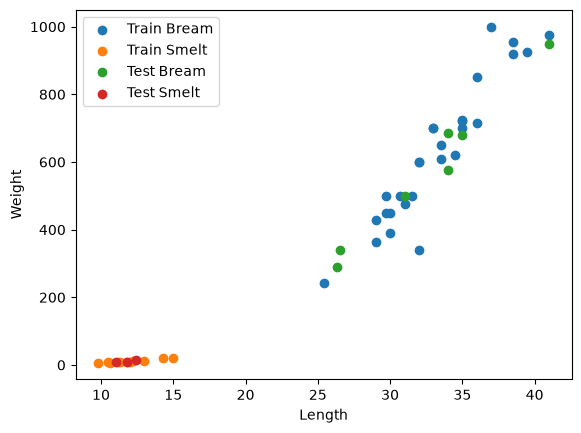

In [12]:
# 6. 데이터 탐색
# 스케일링 전 데이터 산점도

plt.figure()

# 훈련 데이터 - Bream
plt.scatter(
    X_train[y_train == 1]["Length"],
    X_train[y_train == 1]["Weight"],
    label="Train Bream"
)

# 훈련 데이터 - Smelt
plt.scatter(
    X_train[y_train == 0]["Length"],
    X_train[y_train == 0]["Weight"],
    label="Train Smelt"
)

# 테스트 데이터 - Bream
plt.scatter(
    X_test[y_test == 1]["Length"],
    X_test[y_test == 1]["Weight"],
    label="Test Bream"
)

# 테스트 데이터 - Smelt
plt.scatter(
    X_test[y_test == 0]["Length"],
    X_test[y_test == 0]["Weight"],
    label="Test Smelt"
)

plt.xlabel("Length")
plt.ylabel("Weight")
plt.legend()
plt.show()


In [13]:
# 7. 표준화

scaler = StandardScaler()

# 훈련 데이터로 기준을 학습하고 변환
X_train_scaled = scaler.fit_transform(X_train)

# 새로운 학습 없이 훈련 데이터에서 배운 기준으로 테스트 데이터 변환
# scaler는 이미 위에서 학습이 되었음. 
# 만약 .fit_transform() 실행없이 or 실행전에 transform() 호출시 에러발생
# NotFittedError: This StandardScaler instance is not fitted yet

X_test_scaled = scaler.transform(X_test)

In [14]:
# 8. 스케일링 결과 확인
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns,
    index=X_test.index
)

display(X_train_scaled.head())
display(X_test_scaled.head())

,Length,Weight
150,-1.583000,-1.362316
0,-0.183496,-0.649455
152,-1.533372,-1.358650
154,-1.493670,-1.351622
31,1.116753,1.529158


,Length,Weight
1,-0.094166,-0.502788
151,-1.533372,-1.358344
21,0.670103,0.704157
11,0.372336,0.138879
155,-1.473819,-1.347955


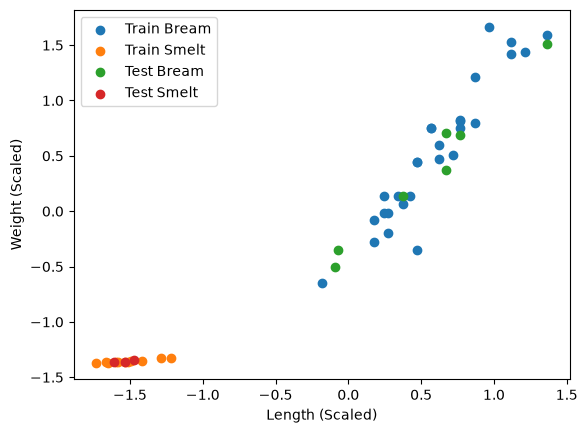

In [15]:
# 9. 스케일링 후 데이터 산점도
plt.figure()

# 훈련 데이터 - Bream
plt.scatter(
    X_train_scaled[y_train == 1]["Length"],
    X_train_scaled[y_train == 1]["Weight"],
    label="Train Bream"
)

# 훈련 데이터 - Smelt
plt.scatter(
    X_train_scaled[y_train == 0]["Length"],
    X_train_scaled[y_train == 0]["Weight"],
    label="Train Smelt"
)

# 테스트 데이터 - Bream
plt.scatter(
    X_test_scaled[y_test == 1]["Length"],
    X_test_scaled[y_test == 1]["Weight"],
    label="Test Bream"
)

# 테스트 데이터 - Smelt
plt.scatter(
    X_test_scaled[y_test == 0]["Length"],
    X_test_scaled[y_test == 0]["Weight"],
    label="Test Smelt"
)

plt.xlabel("Length (Scaled)")
plt.ylabel("Weight (Scaled)")
plt.legend()
plt.show()

In [16]:
# 10. KNN 모델 생성
kn = KNeighborsClassifier(
    n_neighbors=5
)


In [18]:
# 11. 스케일링된 훈련 데이터로 모델 학습
kn.fit(X_train_scaled, y_train);

In [19]:
# 12. 스케일링된 테스트 데이터로 예측
y_pred = kn.predict(X_test_scaled)

In [20]:
# 13. 모델 평가
accuracy = accuracy_score(y_test, y_pred)

print("예측값:", y_pred)
print("실제값:", y_test.values)
print("테스트 정확도:", accuracy)

예측값: [1 0 1 1 0 1 1 1 0 1]
실제값: [1 0 1 1 0 1 1 1 0 1]
테스트 정확도: 1.0


2. 데이터 분할 실습

1) fish.csv 데이터셋의 Perch(농어류)와 Pike(강꼬치고기)를 선택하고, 변수는 Length와 Height를 사용

In [21]:
# 데이터 불러오기
fish = pd.read_csv(
    "https://raw.githubusercontent.com/rickiepark/hg-mldl/master/fish.csv"
)

# Perch와 Pike만 선택
fish2 = fish[fish["Species"].isin(["Perch", "Pike"])]

# 입력 데이터
X = fish2[["Length", "Height"]]

# 정답(타깃) 데이터
y = fish2["Species"]

print(X.head())
print(y.unique())

    Length  Height
72     8.4  2.1120
73    13.7  3.5280
74    15.0  3.8240
75    16.2  4.5924
76    17.4  4.5880
<ArrowStringArray>
['Perch', 'Pike']
Length: 2, dtype: str


2) penguins.csv 데이터셋

In [22]:
penguins = pd.read_csv(
    "https://raw.githubusercontent.com/cran/palmerpenguins/master/inst/extdata/penguins.csv"
)
# 결측치 제거
penguins = penguins.dropna()

# Adelie와 Gentoo만 선택
penguins = penguins[
    penguins["species"].isin(["Adelie", "Gentoo"])
]

# 입력 데이터
X = penguins[["bill_length_mm", "body_mass_g"]]

# 타깃 데이터
y = penguins["species"]
print(X.head())
print(y.unique())

   bill_length_mm  body_mass_g
0            39.1       3750.0
1            39.5       3800.0
2            40.3       3250.0
4            36.7       3450.0
5            39.3       3650.0
<ArrowStringArray>
['Adelie', 'Gentoo']
Length: 2, dtype: str


3) iris.csv 데이터셋 사용

In [23]:
# y 클래스가 3개인 경우

iris = pd.read_csv(
    "https://raw.githubusercontent.com/duchesnay/pystatsml/master/datasets/iris.csv"
)
# 입력 데이터
X = iris[["sepal_length", "petal_length"]]

# 타깃 데이터
y = iris["species"]

print(X.head())
print(y.unique())

   sepal_length  petal_length
0           5.1           1.4
1           4.9           1.4
2           4.7           1.3
3           4.6           1.5
4           5.0           1.4
<ArrowStringArray>
['setosa', 'versicolor', 'virginica']
Length: 3, dtype: str
